# 06 — Context-profile complementarity for generator attribution

This notebook asks whether the **shape of context utility** contains generator-source information beyond a short-context likelihood baseline and cheap stylistic features.

The pilot uses the existing Ghostbuster GPT/Claude machine-text pool because both generators are available for the same underlying source IDs across the same three domains. No new LM scoring is required: `00a_compute_context_utility.ipynb` already saves

\[
L_8, L_{32}, L_{128}, L_{256}
\]

and therefore

\[
C=(U(32),U(128),U(256)), \qquad U(k)=L_8-L_k.
\]

The primary comparison is

\[
B \quad \text{vs.} \quad B+C,
\]

where

\[
B=(L_8,\text{mean sentence length},\text{type-token ratio},\text{function-word rate}).
\]

This is **not** a mathematical orthogonality test. Operationally, it tests whether the multi-scale conditional-loss profile adds **incremental generator-attribution information** beyond short-context predictive difficulty and simple stylistic cues.

We also compare `B+U256` against `B+C`. If the full profile beats the single long-range contrast, the *shape across context scales* carries information beyond total long-vs-short utility.


## Design constraints

- Target: pairwise GPT vs. Claude attribution.
- Unit of splitting: matched `(domain, group_id)` source pair, **not individual generations**.
- Both GPT and Claude versions of a source always stay on the same side of a split.
- All methods use the exact same complete-case document pool.
- 20 overlapping 80/20 source-group splits, mirroring the split-robustness discipline used in §5.5.
- Primary metric: AUROC.
- Secondary metrics: balanced accuracy, accuracy, and F1.
- Split summaries use mean, median, IQR, range, and positive-on-N/20; the 20 overlapping splits are **not** treated as independent replications.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, balanced_accuracy_score, f1_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("reproduction root:", ROOT)
print("project root:", PROJECT_ROOT)


reproduction root: ..
project root: /home/user/Downloads/TemporalContextResearch


## Load the frozen Ghostbuster text and context-loss cache

`00c_prepare_ghostbuster_data.ipynb` creates the raw 9,000-document detector pool. This pilot uses only GPT and Claude. `00a_compute_context_utility.ipynb` writes the four raw context losses as well as U(k), so L8 is available without additional GPU work.


In [2]:
RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"
assert RAW_PATH.exists(), RAW_PATH
assert CTX_PATH.exists(), f"{CTX_PATH} is missing. Run 00a_compute_context_utility.ipynb first."
raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()
required_raw = {"row_id", "domain", "generator", "group_id", "text"}
required_ctx = {"row_id","context_loss_8","context_loss_32","context_loss_128","context_loss_256","context_u_32","context_u_128","context_u_256"}
assert required_raw <= set(raw.columns), sorted(required_raw - set(raw.columns))
assert required_ctx <= set(ctx.columns), sorted(required_ctx - set(ctx.columns))
print("raw:", raw.shape)
print("context cache:", ctx.shape)
print(raw.groupby(["source", "domain", "generator"]).size())


raw: (9000, 10)
context cache: (9000, 8)
source       domain  generator
claude_eval  essay   claude       1000
             reuter  claude       1000
             wp      claude       1000
original     essay   gpt          1000
                     human        1000
             reuter  gpt          1000
                     human        1000
             wp      gpt          1000
                     human        1000
dtype: int64


## Construct the paired GPT/Claude attribution pool

`group_id` is only unique within domain, so the matched splitting key is `pair_id = domain :: group_id`. The audit requires exactly one GPT and one Claude document per retained pair.


In [3]:
machine = raw[raw["generator"].isin(["gpt", "claude"])].copy()
machine["pair_id"] = machine["domain"].astype(str) + "::" + machine["group_id"].astype(str)
pair_counts = machine.groupby("pair_id")["generator"].agg(["size", "nunique"])
valid_pair_ids = pair_counts.index[(pair_counts["size"] == 2) & (pair_counts["nunique"] == 2)]
machine = machine[machine["pair_id"].isin(valid_pair_ids)].copy()
assert (machine.groupby("pair_id")["generator"].nunique() == 2).all()
assert (machine.groupby("pair_id").size() == 2).all()
print("paired source groups before feature filtering:", machine["pair_id"].nunique())
print("documents:", len(machine))
print(machine.groupby(["domain", "generator"]).size())


paired source groups before feature filtering: 3000
documents: 6000
domain  generator
essay   claude       1000
        gpt          1000
reuter  claude       1000
        gpt          1000
wp      claude       1000
        gpt          1000
dtype: int64


## Cheap stylistic baseline features

The controls are CPU-only: mean sentence length, type-token ratio, and function-word rate. They are not intended as a frontier attribution system; they absorb obvious lexical/style differences. Raw word count is saved as an audit variable but is not included in the primary baseline.


In [4]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")
FUNCTION_WORDS = set("a about above after again against all am an and any are as at be because been before being below between both but by can could did do does doing down during each few for from further had has have having he her here hers herself him himself his how i if in into is it its itself just me more most my myself no nor not now of off on once only or other our ours ourselves out over own same she should so some such than that the their theirs them themselves then there these they this those through to too under until up very was we were what when where which while who whom why will with would you your yours yourself yourselves".split())

def stylistic_features(text):
    text = str(text)
    tokens = [t.lower() for t in WORD_RE.findall(text)]
    n_words = len(tokens)
    if n_words == 0:
        return {"mean_sentence_words":np.nan,"type_token_ratio":np.nan,"function_word_rate":np.nan,"word_count":0}
    sent_counts = [len(WORD_RE.findall(s)) for s in SENTENCE_SPLIT_RE.split(text.strip())]
    sent_counts = [n for n in sent_counts if n > 0]
    return {
        "mean_sentence_words": float(np.mean(sent_counts)) if sent_counts else float(n_words),
        "type_token_ratio": len(set(tokens)) / n_words,
        "function_word_rate": sum(t in FUNCTION_WORDS for t in tokens) / n_words,
        "word_count": n_words,
    }

style = pd.DataFrame([{"row_id":r.row_id, **stylistic_features(r.text)} for r in machine[["row_id","text"]].itertuples(index=False)])
display(style.describe())


,mean_sentence_words,type_token_ratio,function_word_rate,word_count
count,6000.000000,6000.000000,6000.000000,6000.000000
mean,19.561654,0.502547,0.408055,467.194333
std,5.113114,0.077735,0.054590,149.583563
min,5.263158,0.260989,0.228942,13.000000
25%,16.094843,0.450516,0.366041,372.000000
50%,19.652174,0.500902,0.406748,443.000000
75%,22.818182,0.547044,0.447576,556.000000
max,103.000000,0.941176,0.615385,1551.000000


## Merge all frozen features and enforce a common complete-case pool

Every feature set is evaluated on the same rows. Because U(k)=L8-Lk, once L8 is present, adding C is information-equivalent to exposing the corresponding longer-context losses. The scientific question is whether **context-dependent changes in loss** carry attribution information beyond L8 and style.


In [5]:
C = ["context_u_32", "context_u_128", "context_u_256"]
STYLE = ["mean_sentence_words", "type_token_ratio", "function_word_rate"]
B = ["context_loss_8", *STYLE]
work = (machine[["row_id","pair_id","domain","group_id","generator","text"]]
        .merge(ctx[["row_id","context_loss_8","context_loss_32","context_loss_128","context_loss_256",*C]], on="row_id", how="left", validate="one_to_one")
        .merge(style, on="row_id", how="left", validate="one_to_one"))
work = work.dropna(subset=[*B,*C]).copy()
complete_pair_ids = work.groupby("pair_id")["generator"].agg(["size","nunique"]).query("size == 2 and nunique == 2").index
work = work[work["pair_id"].isin(complete_pair_ids)].copy()
work["label"] = (work["generator"] == "claude").astype(int)
assert (work.groupby("pair_id").size() == 2).all()
assert (work.groupby("pair_id")["label"].nunique() == 2).all()
print("complete paired source groups:", work["pair_id"].nunique())
print("documents:", len(work))
print(work.groupby(["domain","generator"]).size())
FEATURE_AUDIT_PATH = RESULTS / "context_profile_generator_attribution_features.parquet"
work.drop(columns=["text"]).to_parquet(FEATURE_AUDIT_PATH, index=False)
print("saved:", FEATURE_AUDIT_PATH)


complete paired source groups: 2860
documents: 5720
domain  generator
essay   claude       1000
        gpt          1000
reuter  claude        982
        gpt           982
wp      claude        878
        gpt           878
dtype: int64
saved: ../results/context_profile_generator_attribution_features.parquet


## Feature sets

The headline ablation is `B` versus `B+C`.

Diagnostics:
- `Style`: cheap stylistic controls only
- `L8`: short-context predictive difficulty only
- `B`: style + L8
- `B+U256`: one long-vs-short contrast
- `B+C`: full context-scale profile

If `B+C > B+U256 > B`, attribution benefits not only from total long-range utility but also from **where utility accumulates across context scales**.


In [6]:
FEATURE_SETS = {
    "Style": STYLE,
    "L8": ["context_loss_8"],
    "B": B,
    "B+U256": [*B, "context_u_256"],
    "B+C": [*B, *C],
}
for name, cols in FEATURE_SETS.items(): print(name, "->", cols)


Style -> ['mean_sentence_words', 'type_token_ratio', 'function_word_rate']
L8 -> ['context_loss_8']
B -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate']
B+U256 -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'context_u_256']
B+C -> ['context_loss_8', 'mean_sentence_words', 'type_token_ratio', 'function_word_rate', 'context_u_32', 'context_u_128', 'context_u_256']


## Protocol-matched 20-split attribution experiment

For each seed, unique source-pair IDs are permuted and split 80/20. GPT/Claude documents for each source remain together. Features are standardized on training data only, followed by balanced logistic regression.


In [7]:
def make_classifier():
    return Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced", solver="lbfgs", max_iter=2000, random_state=0))])

pair_ids = np.array(sorted(work["pair_id"].unique()))
rows = []
for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(pair_ids))
    split = int(0.8 * len(pair_ids))
    train_ids, test_ids = set(pair_ids[perm[:split]]), set(pair_ids[perm[split:]])
    assert train_ids.isdisjoint(test_ids)
    train = work[work["pair_id"].isin(train_ids)].copy()
    test = work[work["pair_id"].isin(test_ids)].copy()
    assert train["label"].mean() == 0.5 and test["label"].mean() == 0.5
    for method, cols in FEATURE_SETS.items():
        model = make_classifier(); model.fit(train[cols], train["label"])
        prob = model.predict_proba(test[cols])[:,1]
        pred = (prob >= 0.5).astype(int)
        y = test["label"].to_numpy()
        rows.append({"seed":seed,"method":method,"n_train_pairs":len(train_ids),"n_test_pairs":len(test_ids),"n_train_docs":len(train),"n_test_docs":len(test),"auroc":roc_auc_score(y,prob),"accuracy":accuracy_score(y,pred),"balanced_accuracy":balanced_accuracy_score(y,pred),"f1":f1_score(y,pred)})
split_results = pd.DataFrame(rows)
RESULTS_PATH = RESULTS / "context_profile_generator_attribution_split_results.csv"
split_results.to_csv(RESULTS_PATH, index=False)
print("saved:", RESULTS_PATH)
display(split_results.groupby("method")[["auroc","balanced_accuracy","accuracy","f1"]].mean().sort_values("auroc", ascending=False))


saved: ../results/context_profile_generator_attribution_split_results.csv


,auroc,balanced_accuracy,accuracy,f1
method,,,,
B+C,0.775560,0.706425,0.706425,0.704551
B+U256,0.775012,0.709135,0.709135,0.707224
B,0.749482,0.689729,0.689729,0.688678
Style,0.733567,0.680463,0.680463,0.679123
L8,0.632981,0.597990,0.597990,0.588321


## Matched split-level deltas

Primary contrasts:

- `B+C vs B`: incremental context-profile information beyond baseline
- `B+U256 vs B`: value of a single long-range contrast
- `B+C vs B+U256`: extra value of the multi-scale shape


In [8]:
COMPARISONS = {"B+C vs B":("B+C","B"),"B+U256 vs B":("B+U256","B"),"B+C vs B+U256":("B+C","B+U256"),"B vs L8":("B","L8"),"B vs Style":("B","Style")}
METRICS = ["auroc","balanced_accuracy","accuracy","f1"]
wide = split_results.set_index(["seed","method"])
delta_rows=[]
for comparison,(a,b) in COMPARISONS.items():
    for seed in range(20):
        row={"seed":seed,"comparison":comparison,"method_a":a,"method_b":b}
        for metric in METRICS: row[f"delta_{metric}"] = wide.loc[(seed,a),metric]-wide.loc[(seed,b),metric]
        delta_rows.append(row)
deltas=pd.DataFrame(delta_rows)
DELTAS_PATH=RESULTS/"context_profile_generator_attribution_deltas.csv"
deltas.to_csv(DELTAS_PATH,index=False)
print("saved:", DELTAS_PATH)
display(deltas.head())


saved: ../results/context_profile_generator_attribution_deltas.csv


,seed,comparison,method_a,method_b,delta_auroc,delta_balanced_accuracy,delta_accuracy,delta_f1
0,0,B+C vs B,B+C,B,0.027040,0.018357,0.018357,0.017770
1,1,B+C vs B,B+C,B,0.019423,0.010490,0.010490,0.003550
2,2,B+C vs B,B+C,B,0.041545,0.028846,0.028846,0.026439
3,3,B+C vs B,B+C,B,0.022654,0.021853,0.021853,0.019134
4,4,B+C vs B,B+C,B,0.028385,0.006119,0.006119,0.007473


## Split-dispersion summary

The overlapping splits are robustness perturbations, not independent replications. We summarize mean, median, IQR, range, and positive-on-N/20 rather than constructing a conventional confidence interval across seeds.


In [9]:
summary_rows=[]
for comparison,sub in deltas.groupby("comparison",sort=False):
    out={"comparison":comparison,"n_splits":len(sub)}
    for metric in METRICS:
        vals=sub[f"delta_{metric}"].to_numpy()
        out[f"mean_delta_{metric}"]=vals.mean(); out[f"median_delta_{metric}"]=np.median(vals)
        out[f"q25_delta_{metric}"]=np.quantile(vals,.25); out[f"q75_delta_{metric}"]=np.quantile(vals,.75)
        out[f"min_delta_{metric}"]=vals.min(); out[f"max_delta_{metric}"]=vals.max()
        out[f"positive_delta_{metric}"]=int((vals>0).sum()); out[f"nonnegative_delta_{metric}"]=int((vals>=0).sum())
    summary_rows.append(out)
summary=pd.DataFrame(summary_rows)
SUMMARY_PATH=RESULTS/"context_profile_generator_attribution_summary.csv"
summary.to_csv(SUMMARY_PATH,index=False)
print("saved:",SUMMARY_PATH)
display(summary[["comparison","mean_delta_auroc","median_delta_auroc","q25_delta_auroc","q75_delta_auroc","positive_delta_auroc","mean_delta_balanced_accuracy","positive_delta_balanced_accuracy","mean_delta_f1","positive_delta_f1"]])


saved: ../results/context_profile_generator_attribution_summary.csv


,comparison,mean_delta_auroc,median_delta_auroc,q25_delta_auroc,q75_delta_auroc,positive_delta_auroc,mean_delta_balanced_accuracy,positive_delta_balanced_accuracy,mean_delta_f1,positive_delta_f1
0,B+C vs B,0.026078,0.023733,0.022390,0.028718,20,0.016696,20,0.015873,20
1,B+U256 vs B,0.025530,0.023971,0.021846,0.030020,20,0.019406,20,0.018547,20
2,B+C vs B+U256,0.000547,0.000695,-0.000949,0.002016,13,-0.002710,5,-0.002673,6
3,B vs L8,0.116501,0.113433,0.107398,0.128031,20,0.091740,20,0.100357,20
4,B vs Style,0.015916,0.017159,0.014548,0.018314,20,0.009266,17,0.009555,18


## Headline figure

Points are protocol-matched split perturbations; horizontal segments are split means.


saved: ../figures/context_profile_generator_attribution.pdf
saved: ../figures/context_profile_generator_attribution.png


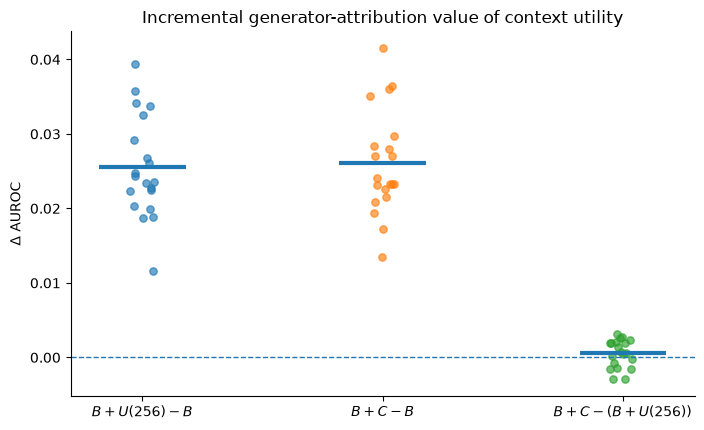

In [10]:
plot_comparisons=["B+U256 vs B","B+C vs B","B+C vs B+U256"]
fig,ax=plt.subplots(figsize=(7.2,4.4)); jitter_rng=np.random.default_rng(123)
for i,comparison in enumerate(plot_comparisons):
    vals=deltas.loc[deltas["comparison"]==comparison,"delta_auroc"].to_numpy()
    jitter=jitter_rng.uniform(-.055,.055,len(vals)); ax.scatter(i+jitter,vals,alpha=.65,s=28); ax.hlines(vals.mean(),i-.18,i+.18,linewidth=3)
ax.axhline(0,linestyle="--",linewidth=1)
ax.set_xticks(range(len(plot_comparisons))); ax.set_xticklabels([r"$B+U(256)-B$",r"$B+C-B$",r"$B+C-(B+U(256))$"])
ax.set_ylabel(r"$\Delta$ AUROC"); ax.set_title("Incremental generator-attribution value of context utility")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); fig.tight_layout()
PDF_PATH=FIGURES/"context_profile_generator_attribution.pdf"; PNG_PATH=FIGURES/"context_profile_generator_attribution.png"
fig.savefig(PDF_PATH,bbox_inches="tight"); fig.savefig(PNG_PATH,dpi=200,bbox_inches="tight")
print("saved:",PDF_PATH); print("saved:",PNG_PATH); plt.show()


## Interpretation checklist

1. **Does B+C beat B?** If yes, context-dependent loss changes add attribution information beyond L8 and style.
2. **Does B+U256 beat B?** If yes, one long-vs-short contrast adds information.
3. **Does B+C beat B+U256?** If yes, the scale profile itself matters, which is most relevant to a dependency-*range* interpretation.
4. Report median, IQR, range, and positive-on-N/20; do not treat overlapping splits as independent.
5. A positive result still does not prove U(k) uniquely measures source-model dependency organization. It establishes incremental predictive information associated with context-sensitive loss changes under the frozen scorer.


## Headline result helper


In [11]:
def report_comparison(name):
    row=summary.loc[summary["comparison"]==name].iloc[0]
    print(name)
    print("  AUROC:",f"mean Δ={row['mean_delta_auroc']:+.5f},",f"median Δ={row['median_delta_auroc']:+.5f},",f"IQR=[{row['q25_delta_auroc']:+.5f}, {row['q75_delta_auroc']:+.5f}],",f"positive={int(row['positive_delta_auroc'])}/20")
    print("  balanced accuracy:",f"mean Δ={row['mean_delta_balanced_accuracy']:+.5f},",f"positive={int(row['positive_delta_balanced_accuracy'])}/20")
    print("  F1:",f"mean Δ={row['mean_delta_f1']:+.5f},",f"positive={int(row['positive_delta_f1'])}/20")
for name in ["B+C vs B","B+U256 vs B","B+C vs B+U256"]: report_comparison(name)


B+C vs B
  AUROC: mean Δ=+0.02608, median Δ=+0.02373, IQR=[+0.02239, +0.02872], positive=20/20
  balanced accuracy: mean Δ=+0.01670, positive=20/20
  F1: mean Δ=+0.01587, positive=20/20
B+U256 vs B
  AUROC: mean Δ=+0.02553, median Δ=+0.02397, IQR=[+0.02185, +0.03002], positive=20/20
  balanced accuracy: mean Δ=+0.01941, positive=20/20
  F1: mean Δ=+0.01855, positive=20/20
B+C vs B+U256
  AUROC: mean Δ=+0.00055, median Δ=+0.00070, IQR=[-0.00095, +0.00202], positive=13/20
  balanced accuracy: mean Δ=-0.00271, positive=5/20
  F1: mean Δ=-0.00267, positive=6/20
